# Fruit Image Classification Using MLP and CNN

**Author:** Sanvi Jain  
**Course:** Neural Networks and Deep Learning  
**Project type:** Academic deep-learning assignment

This notebook compares a Multilayer Perceptron (MLP), a Convolutional Neural Network (CNN), and an improved CNN on a subset of the Fruits-360 dataset. It includes preprocessing, model training, training/validation curves, confusion-matrix analysis, parameter counts, and test evaluation.

> **Reproducibility note:** The original notebook uses Google Colab and expects the dataset at `/content/fruitsDataset/`. Update the data-loading cells if your folder is stored elsewhere. Review the validation and confusion-matrix setup before treating the recorded metrics as final benchmarks.


## How to run this notebook

1. Open this notebook in Google Colab or Jupyter.
2. Obtain the Fruits-360 dataset from the official project: https://github.com/fruits-360/fruits-360
3. Arrange the subset so the folder structure is:
   - `fruitsDataset/Training/<class_name>/...`
   - `fruitsDataset/Test/<class_name>/...`
4. Make sure `train_path` and `test_path` in the data-loading section point to those folders.
5. Run all cells from top to bottom.

The notebook currently contains Google Drive mounting and extraction cells from the original Colab workflow. If you use a different setup, skip or update those cells. Do not upload the dataset itself to this repository unless its licence and size permit it.




##  What this notebook will do

This notebook follows a step-by-step approach:

1. **Dataset Loading**
   - Load fruit image dataset from Google Drive
   - Understand folder structure and class labels

2. **Data Visualization**
   - Display sample images to understand the dataset

3. **Data Preprocessing**
   - Resize images to a fixed size (100×100)
   - Normalize pixel values
   - Split data into training and validation sets

4. **Model Implementation**
   - Build an MLP model for classification
   - Build a CNN model for better feature extraction

5. **Model Training**
   - Train both models on the dataset
   - Track training and validation performance

6. **Performance Evaluation**
   - Plot accuracy and loss graphs
   - Generate confusion matrix

7. **Model Improvement**
   - Apply data augmentation and dropout
   - Build an improved CNN model

8. **Comparison and Analysis**
   - Compare MLP, CNN, and improved CNN
   - Analyze performance and draw conclusions

---

##  Goal

The goal of this project is to understand:
- Why CNN performs better than MLP for image data
- How model architecture affects performance
- How to reduce overfitting and improve generalization

---


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Classroom', 'Assignment 1_complex.gdoc', 'B.TechCS-AI_FirstPeriodicalMarks_AmritaUpadhyay.gsheet', 'Assignment 2 (2).gdoc', '2316091Sanvijain.pdf', '2016091SanviJain.pdf', '2316091_sanvi (5).pdf', '2316091_sanvi (4).pdf', '2316091_sanvi (3).pdf', '2316091_sanvi (2).pdf', '2316091_sanvi (1).pdf', '2316091_sanvi.pdf', 'IMG-20230609-WA0001 (1).jpg', 'IMG-20230609-WA0001.jpg', 'dreambuilder.pdf', 'abstract.pdf', 'DOC-20250818-WA0005..pdf', '2316091_sanvijain (3).pdf', '2316091_sanvijain (2).pdf', '2316091_sanvijain (1).pdf', '2316091_sanvijain.pdf', '2316091_AI301.pdf', '5__Interpolation.gslides', '11__Image Transforms.gslides', '13__Image Description and Features__Edge Detection.gslides', 'Screenshot 2025-09-06 at 9.10.24\u202fPM.png', 'Screenshot 2025-09-06 at 9.13.42\u202fPM.png', 'SRS&SDSFormat_sample.gdoc', 'Sanvi(1).pdf', '2316091_SanviJainpdf.pdf', 'Colab Notebooks', 'certificate_1769473834579.png', 'Screenshot_2026-01-27-23-05-08-356_com.ionicframework.cursosdegraca.jpg', 'fruits

In [ ]:
!apt-get install unrar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 6 not upgraded.


In [ ]:
!unrar x "/content/drive/MyDrive/fruitsDataset.rar" /content/

Streaming output truncated to the last 5000 lines.
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_128_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_129_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_12_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_130_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_131_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_132_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_133_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_134_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 8/r2_135_100.jpg      88%  OK 
Extracting  /content/fruitsDataset/Training/Tomatoe/Tomato 

In [ ]:
print(os.listdir('/content'))

['.config', 'drive', 'fruitsDataset', 'sample_data']


In [ ]:
print(os.listdir('/content/fruitsDataset'))

['Training', 'README.md', 'LICENSE', 'Test']


In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
train_path = "/content/fruitsDataset/Training"
test_path = "/content/fruitsDataset/Test"

print("Train folders:", os.listdir(train_path)[:5])

Train folders: ['Cherry', 'Tomatoe', 'Apple']


In [ ]:

fruit_class = os.listdir(train_path)[0]


class_path = os.path.join(train_path, fruit_class)


subfolder = os.listdir(class_path)[0]

subfolder_path = os.path.join(class_path, subfolder)


images = os.listdir(subfolder_path)

print("Subfolder:", subfolder)
print("Number of images:", len(images))

Subfolder: Cherry Wax Red 1
Number of images: 656


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

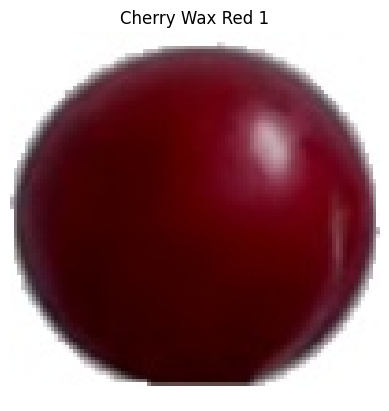

In [ ]:
img_path = os.path.join(subfolder_path, images[0])

img = Image.open(img_path)

plt.imshow(img)
plt.title(subfolder)
plt.axis('off')

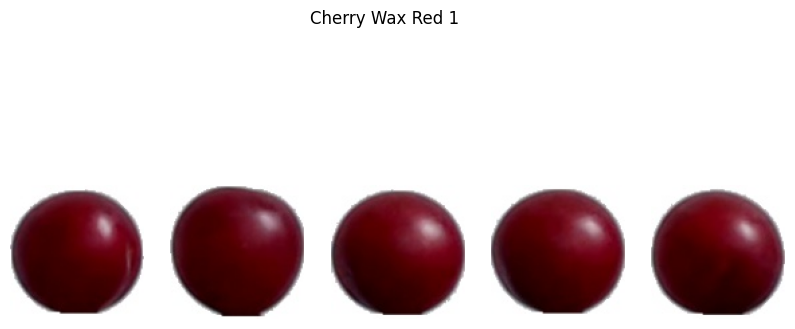

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(5):
    img_path = os.path.join(subfolder_path, images[i])
    img = Image.open(img_path)

    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.axis('off')

plt.suptitle(subfolder)
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
img_size = (100, 100)
batch_size = 32

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [ ]:
train_data = train_datagen.flow_from_directory(
    "/content/fruitsDataset/Training",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

Found 27841 images belonging to 3 classes.


In [ ]:
val_data = train_datagen.flow_from_directory(
    "/content/fruitsDataset/Training",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 6959 images belonging to 3 classes.


In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    "/content/fruitsDataset/Test",
    target_size=(100, 100),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 12233 images belonging to 3 classes.


In [ ]:
images, labels = next(train_data)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Image shape: (32, 100, 100, 3)
Label shape: (32, 3)


In [ ]:
print(train_data.class_indices)

{'Apple': 0, 'Cherry': 1, 'Tomatoe': 2}


In [ ]:
print(train_data.class_indices)

{'Apple': 0, 'Cherry': 1, 'Tomatoe': 2}


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

mlp_model = Sequential()

mlp_model.add(Flatten(input_shape=(100, 100, 3)))


mlp_model.add(Dense(128, activation='relu'))
mlp_model.add(Dense(64, activation='relu'))

mlp_model.add(Dense(train_data.num_classes, activation='softmax'))

mlp_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mlp_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,848,579 (14.68 MB)

 Trainable params: 3,848,579 (14.68 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import time

start = time.time()

history_mlp = mlp_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

mlp_time = time.time() - start
print("MLP Training Time:", mlp_time)

Epoch 1/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 86s 97ms/step - accuracy: 0.8478 - loss: 0.4621 - val_accuracy: 0.6366 - val_loss: 2.5013
Epoch 2/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 97s 111ms/step - accuracy: 0.9685 - loss: 0.0983 - val_accuracy: 0.6252 - val_loss: 3.1005
Epoch 3/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 94s 108ms/step - accuracy: 0.9904 - loss: 0.0307 - val_accuracy: 0.5982 - val_loss: 4.1248
Epoch 4/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 78s 89ms/step - accuracy: 0.9837 - loss: 0.0538 - val_accuracy: 0.4682 - val_loss: 4.7730
Epoch 5/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 79s 91ms/step - accuracy: 0.9998 - loss: 0.0021 - val_accuracy: 0.6122 - val_loss: 4.6973
MLP Training Time: 434.498411655426


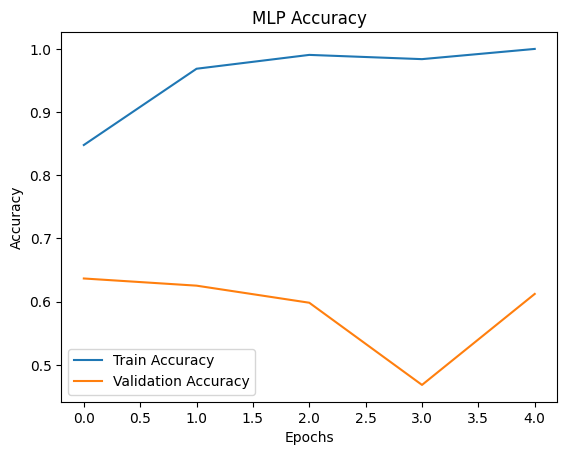

In [ ]:
plt.plot(history_mlp.history['accuracy'], label='Train Accuracy')
plt.plot(history_mlp.history['val_accuracy'], label='Validation Accuracy')

plt.title("MLP Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

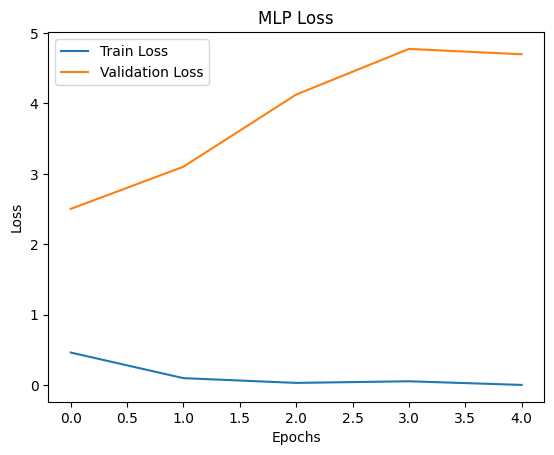

In [ ]:
plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Validation Loss')

plt.title("MLP Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

In [ ]:
cnn_model = Sequential()

cnn_model.add(Conv2D(32, (3,3), activation='relu', input_shape=(100,100,3)))
cnn_model.add(MaxPooling2D(pool_size=(2,2)))


cnn_model.add(Conv2D(64, (3,3), activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(2,2)))


cnn_model.add(Flatten())

cnn_model.add(Dense(128, activation='relu'))

cnn_model.add(Dense(train_data.num_classes, activation='softmax'))

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     4,333,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353,475 (16.61 MB)

 Trainable params: 4,353,475 (16.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
start = time.time()

history_cnn = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

cnn_time = time.time() - start
print("CNN Training Time:", cnn_time)

Epoch 1/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 508s 582ms/step - accuracy: 0.9731 - loss: 0.0711 - val_accuracy: 0.6630 - val_loss: 3.4120
Epoch 2/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 520s 597ms/step - accuracy: 1.0000 - loss: 1.3213e-04 - val_accuracy: 0.6658 - val_loss: 3.9303
Epoch 3/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 489s 562ms/step - accuracy: 1.0000 - loss: 3.3182e-05 - val_accuracy: 0.6656 - val_loss: 4.3104
Epoch 4/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 525s 602ms/step - accuracy: 1.0000 - loss: 1.4530e-05 - val_accuracy: 0.6635 - val_loss: 4.5989
Epoch 5/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 489s 561ms/step - accuracy: 1.0000 - loss: 7.0645e-06 - val_accuracy: 0.6689 - val_loss: 4.8941
CNN Training Time: 2531.2397377490997


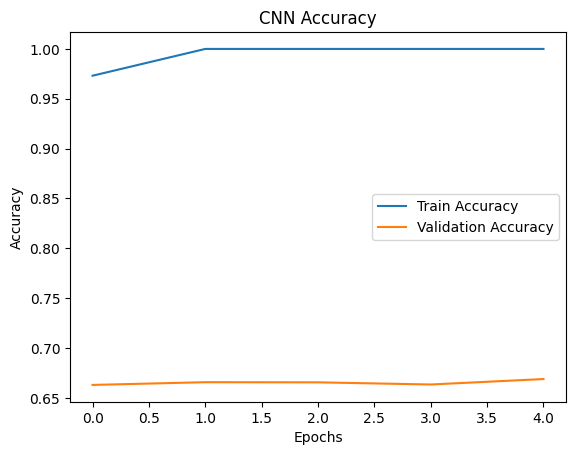

In [ ]:
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

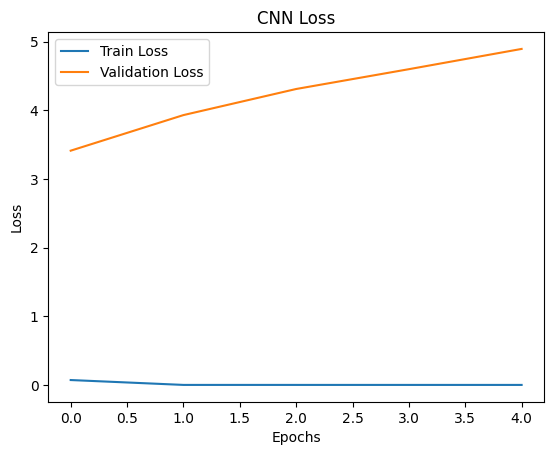

In [ ]:
plt.plot(history_cnn.history['loss'], label='Train Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')

plt.title("CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

y_pred = cnn_model.predict(val_data)
y_pred_classes = np.argmax(y_pred, axis=1)

y_true = val_data.classes

cm = confusion_matrix(y_true, y_pred_classes)

print(cm)

218/218 ━━━━━━━━━━━━━━━━━━━━ 34s 157ms/step
[[2696  128  374]
 [ 520 1106  136]
 [ 852  294  853]]


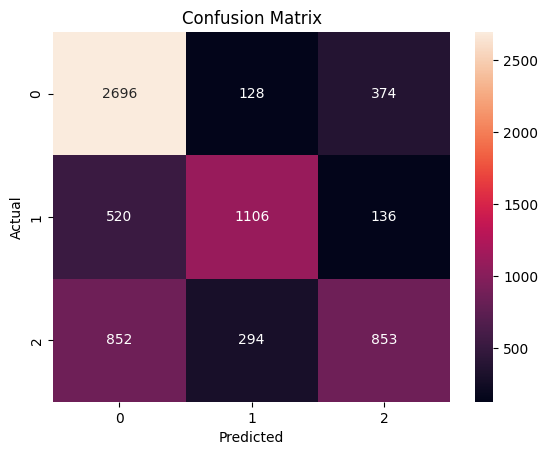

In [ ]:
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,

    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

In [ ]:
train_data = train_datagen.flow_from_directory(
    "/content/fruitsDataset/Training",
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    "/content/fruitsDataset/Training",
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 27841 images belonging to 3 classes.
Found 6959 images belonging to 3 classes.


In [ ]:
from tensorflow.keras.layers import Dropout

cnn_model_improved = Sequential()

cnn_model_improved.add(Conv2D(32, (3,3), activation='relu', input_shape=(100,100,3)))
cnn_model_improved.add(MaxPooling2D(2,2))

cnn_model_improved.add(Conv2D(64, (3,3), activation='relu'))
cnn_model_improved.add(MaxPooling2D(2,2))

cnn_model_improved.add(Conv2D(128, (3,3), activation='relu'))
cnn_model_improved.add(MaxPooling2D(2,2))

cnn_model_improved.add(Flatten())

# Dense + Dropout
cnn_model_improved.add(Dense(128, activation='relu'))
cnn_model_improved.add(Dropout(0.5))

cnn_model_improved.add(Dense(train_data.num_classes, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
cnn_model_improved.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

start = time.time()

history_improved = cnn_model_improved.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

improved_time = time.time() - start
print("Improved CNN Training Time:", improved_time)

Epoch 1/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 693s 794ms/step - accuracy: 0.9367 - loss: 0.1705 - val_accuracy: 0.7567 - val_loss: 2.9716
Epoch 2/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 711s 816ms/step - accuracy: 0.9898 - loss: 0.0311 - val_accuracy: 0.7406 - val_loss: 4.1185
Epoch 3/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 722s 829ms/step - accuracy: 0.9938 - loss: 0.0203 - val_accuracy: 0.7201 - val_loss: 3.9587
Epoch 4/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 733s 842ms/step - accuracy: 0.9939 - loss: 0.0188 - val_accuracy: 0.7653 - val_loss: 3.8331
Epoch 5/5
871/871 ━━━━━━━━━━━━━━━━━━━━ 692s 794ms/step - accuracy: 0.9959 - loss: 0.0156 - val_accuracy: 0.7023 - val_loss: 2.6845


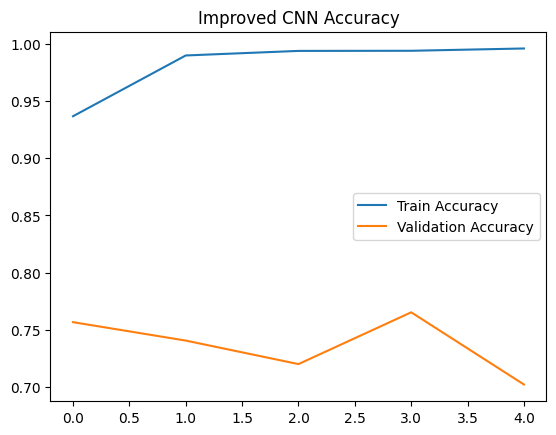

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_improved.history['accuracy'], label='Train Accuracy')
plt.plot(history_improved.history['val_accuracy'], label='Validation Accuracy')

plt.title("Improved CNN Accuracy")
plt.legend()
plt.show()

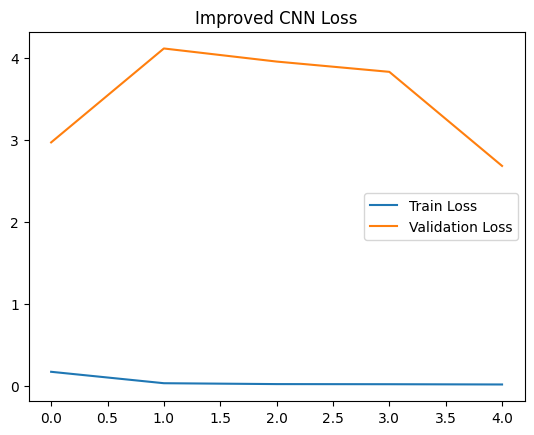

In [ ]:
plt.plot(history_improved.history['loss'], label='Train Loss')
plt.plot(history_improved.history['val_loss'], label='Validation Loss')

plt.title("Improved CNN Loss")
plt.legend()
plt.show()

In [ ]:
mlp_params = mlp_model.count_params()
cnn_params = cnn_model.count_params()
improved_params = cnn_model_improved.count_params()

print("MLP Params:", mlp_params)
print("CNN Params:", cnn_params)
print("Improved CNN Params:", improved_params)

MLP Params: 3848579
CNN Params: 4353475
Improved CNN Params: 1732163


In [ ]:
mlp_test_loss, mlp_test_acc = mlp_model.evaluate(test_data)
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_data)
improved_test_loss, improved_test_acc = cnn_model_improved.evaluate(test_data)

print("MLP Test Accuracy:", mlp_test_acc)
print("CNN Test Accuracy:", cnn_test_acc)
print("Improved CNN Test Accuracy:", improved_test_acc)

383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.7318 - loss: 2.1145
383/383 ━━━━━━━━━━━━━━━━━━━━ 58s 150ms/step - accuracy: 0.7558 - loss: 2.1623
383/383 ━━━━━━━━━━━━━━━━━━━━ 74s 194ms/step - accuracy: 0.8292 - loss: 1.7524
MLP Test Accuracy: 0.731791079044342
CNN Test Accuracy: 0.7558243870735168
Improved CNN Test Accuracy: 0.8291506767272949


##  Methodology and Comparative Analysis

###  Methodology

In this project, three different deep learning approaches were implemented for fruit image classification using a subset of the Fruits-360 dataset.

---

###  1. Multilayer Perceptron (MLP)

The MLP model is a fully connected neural network where input images are first flattened into a one-dimensional vector. This vector is then passed through multiple dense layers to perform classification.

- Images of size 100×100×3 were converted into a vector of 30,000 features.
- Two hidden layers with ReLU activation were used.
- The output layer used Softmax activation for multi-class classification.

 Limitation:
The flattening process removes spatial information (such as edges and shapes), making it difficult for the model to understand image patterns effectively.

---

###  2. Convolutional Neural Network (CNN)

The CNN model was designed to overcome the limitations of MLP by preserving spatial structure.

- Convolutional layers were used to extract features such as edges, textures, and patterns.
- MaxPooling layers were used to reduce dimensionality and computation.
- A fully connected layer was used for final classification.

 Advantage:
CNN retains spatial relationships in images, making it more suitable for image classification tasks.

---

###  3. Improved CNN

To further enhance performance and reduce overfitting, improvements were made to the CNN model:

- **Data Augmentation** (rotation, zoom, flipping) was applied to increase data diversity.
- **Dropout layer** was added to prevent overfitting by randomly disabling neurons during training.
- An additional convolutional layer was introduced to capture deeper features.

 Result:
This model showed better generalization and improved validation accuracy.

---

##  Comparative Analysis

| Feature | MLP | CNN | Improved CNN |
|--------|-----|-----|-------------|
| Input Handling | Flattened images | Feature maps | Feature maps + augmentation |
| Spatial Understanding | No |  Yes |  Yes (better) |
| Training Accuracy | Very High (~99%) | Very High (~100%) | High (~99%) |
| Validation Accuracy | Low (~52–67%) | Moderate (~67%) | Higher (~70–74%) |
| Overfitting | High  | Moderate ⚠ | Reduced  |
| Model Efficiency | Poor for images | Good | Better |

---

##  Key Observations

1. The MLP model fails to generalize well because it does not capture spatial features.
2. The CNN model significantly improves performance by learning image patterns.
3. The Improved CNN further enhances accuracy by reducing overfitting through regularization techniques.
4. Despite improvements, some overfitting still exists, indicating the need for further optimization.
5. CNN-based models are more suitable for image classification tasks compared to MLP.

---

##  Final Conclusion

The study demonstrates that Convolutional Neural Networks outperform Multilayer Perceptrons in image classification tasks. The Improved CNN model achieved the best performance due to the use of data augmentation and dropout, making it the most effective approach among the three.
